## Summary and Framing of Problem ##

Expected Goals, or $xG$, models quantify shot quality by estimating the conditional probability $\mathbb{P}(Y=1|X)$, where $Y$ is a binary value denoting whether a shot went in or not.

Rather than treating shot outcome as a binary classification problem, xG modelling estimates continuous probabilities, hence traditional classification metrics such as Accuracy or $F_{1}$-score do not work because they rely on an arbitrary decision threshold. Instead, we evaluate model quality using proper scoring rules, like log loss and the Brier Score which penalise poorly calibrated estimates.

On top of this, in order to prevent temporal data leakage and evaluate generalisability on unseen fixtures we split our data by:
 1. **Training data (Seasons 21/22-24/25)**: Used for model parameter estimates.
 2. **Validation data**: Used as a strict temporal
 3. **Test data (Seasons 25/26-26/27)**: Unseen data evaluated strictly once at the end to measure final performance.
 
Throughout this I will be comparing my model's outputs and test scores with that of a predefined downloaded xg model which uses freeze-frame accuracy throughout games to predict xG, on a much larger data set, i.e. the gold standard xG model.

In [1]:
%pip install xgboost
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score, roc_curve
from sklearn.calibration import calibration_curve
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.model_selection import PredefinedSplit
from xgboost import XGBClassifier

# Read cleaned dataset
df = pd.read_csv("shots_cleaned_with_distance.csv")
print(f"Dataset Loaded: {df.shape[0]} total shots across {df['season'].nunique()} seasons.")

  Using cached xgboost-2.1.4-py3-none-manylinux_2_28_x86_64.whl (223.6 MB)
  Using cached nvidia_nccl_cu12-2.32.3-py3-none-manylinux_2_27_x86_64.whl (351.5 MB)
Note: you may need to restart the kernel to use updated packages.
Dataset Loaded: 50798 total shots across 6 seasons.


In order to facilitate the process we compute an explicit Euclidian distance ($d$) from the ball to the goal centre $(120,40)$ where $$d=\sqrt{(120-x)^2+(40-y)^2}$$
This helps since decision trees split feature spaces using orthogonal cuts $(x>a \text{ or } y>b)$ whereas this provides a smooth gradient.

In [2]:
# Load dataset
df = pd.read_csv("shots_cleaned.csv")

# Pitch center goal coordinates
GOAL_X = 120.0
GOAL_Y = 40.0

# Calculate Euclidean distance to goal center
df["distance_to_goal"] = np.sqrt((GOAL_X - df["x"]) ** 2 + (GOAL_Y - df["y"]) ** 2)

df.to_csv('shots_cleaned_with_distance.csv', index=False)
df[['x', 'y', 'distance_to_goal']].head()

,x,y,distance_to_goal
0,109.560004,43.120001,10.896235
1,108.960004,25.200000,18.464060
2,104.880002,55.840002,21.897946
3,97.439996,38.239999,22.628552
4,107.039996,28.560001,17.286853


# Feature Choice
I define which features are safe to test on and which create bias / benchmark leakage.

In [3]:
# Explicitly whitelist all valid predictor features
features = [
    # Spatial
    "x", "y", "angle_to_goal", "distance_to_goal",
    
    # Context & Situation
    "is_home", "minute", "is_assisted", "is_penalty", 
    "is_open_play", "is_set_piece", "from_corner", "is_free_kick",
    
    # Game State
    "team_goals_before", "opp_goals_before", "score_diff",
    
    # Body Part
    "head", "left_foot", "right_foot", "other_body_part",
    
    # Pre-Shot Action
    "last_action_aerial", "last_action_ball_recovery", "last_action_ball_touch", 
    "last_action_chipped", "last_action_cross", "last_action_dispossessed", 
    "last_action_foul", "last_action_head_pass", "last_action_lay_off", 
    "last_action_none", "last_action_pass", "last_action_rebound", 
    "last_action_standard", "last_action_tackle", "last_action_take_on", 
    "last_action_throughball"]

target = "result"

# Guardrail to ensure no target or benchmark leakage
unsafe_cols = ["season", "team", "result", "xg"]
for col in unsafe_cols:
    if col in features:
        raise ValueError(f"CRITICAL LEAK: Remove {col} from features list.")

X = df[features]
y = df[target]

print(f"Model will train on {len(features)} features. Data shape: {X.shape}")

Model will train on 35 features. Data shape: (50798, 35)


In [4]:
# Define temporal boundaries
train_seasons = ["2021/22", "2022/23", "2023/24"]
valid_season = ["2024/25"]
test_seasons = ["2025/26", "2026/27"]

# Create combination mask for GridSearchCV
train_val_mask = df["season"].isin(train_seasons + valid_season)
test_mask = df["season"].isin(test_seasons)

# Slice features and targets
X_train_val = df.loc[train_val_mask, features]
y_train_val = df.loc[train_val_mask, target]

X_test = df.loc[test_mask, features]
y_test = df.loc[test_mask, target]

# Build PredefinedSplit for temporal forward-validation
# -1 indicates training folds (21/22-23/24), 0 indicates validation fold (24/25)
split_index = df.loc[train_val_mask, "season"].map(lambda s: 0 if s in valid_season else -1).values

pds = PredefinedSplit(test_fold=split_index)

print(f"Training Set (21/22 - 23/24): {sum(split_index == -1)} shots")
print(f"Validation Set (24/25):       {sum(split_index == 0)} shots")
print(f"Test Set (25/26 - 26/27):     {len(X_test)} shots")

Training Set (21/22 - 23/24): 29813 shots
Validation Set (24/25):       9844 shots
Test Set (25/26 - 26/27):     11141 shots


We have used temporal-forward validation as opposed to k-fold cross validation since k-fold splits data into k folds randomly, which can leak temporal data as future data points can enter training folds while predicting past validation points but temporal-forward validation has strict forward-looking boundaries that guarantee no leakage by manually assigning past rows to train and future rows to validation. It also takes only 1 times the time for a normal training run as opposed to k, saving us computation time.

# Baseline model design
I make a baseline model using basic predefined hyperparameters and evaluate it on validation and test data.

In [5]:
# Baseline Spatial Model Evaluation (Validation Set: 2024/25)
baseline_features = ["x", "y", "angle_to_goal", "distance_to_goal"]

# Extract train (-1) and validation (0) slices using split_index
train_mask_cv = split_index == -1
valid_mask_cv = split_index == 0

X_train_base = X_train_val[train_mask_cv][baseline_features]
y_train_base = y_train_val[train_mask_cv]

X_val_base = X_train_val[valid_mask_cv][baseline_features]
y_val_base = y_train_val[valid_mask_cv]

# Instantiate baseline model
baseline_xgb = XGBClassifier(n_estimators=100,max_depth=4,learning_rate=0.05,eval_metric="logloss",random_state=42)

# Train on 2021/22 - 2023/24
baseline_xgb.fit(X_train_base, y_train_base)

# Predict probabilities on unseen validation season (2024/25)
preds_val_base = baseline_xgb.predict_proba(X_val_base)[:, 1]

# Metrics for baseline on 2024/25
base_logloss = log_loss(y_val_base, preds_val_base)
base_brier = brier_score_loss(y_val_base, preds_val_base)
base_auc = roc_auc_score(y_val_base, preds_val_base)

# Benchmark Understat xG on the exact same validation set (2024/25)
Understat_val_xg = df.loc[train_val_mask, "xg"].values[valid_mask_cv]
Understat_logloss = log_loss(y_val_base, Understat_val_xg)
Understat_brier = brier_score_loss(y_val_base, Understat_val_xg)
Understat_auc = roc_auc_score(y_val_base, Understat_val_xg)

print("--- BASELINE MODEL RESULTS (VALIDATION SET: 2024/25) ---")
print(f"Baseline Log Loss: {base_logloss:.5f} | Understat xG: {Understat_logloss:.5f}")
print(f"Baseline Brier:    {base_brier:.5f} | Understat xG: {Understat_brier:.5f}")
print(f"Baseline ROC-AUC:  {base_auc:.5f} | Understat xG: {Understat_auc:.5f}")

--- BASELINE MODEL RESULTS (VALIDATION SET: 2024/25) ---
Baseline Log Loss: 0.30166 | Understat xG: 0.27155
Baseline Brier:    0.08536 | Understat xG: 0.07735
Baseline ROC-AUC:  0.73436 | Understat xG: 0.80579


Here we have chosen some basline hyperparameters:

**n_estimators = 100**: 100 trees is the standard initial ensemble size for tabular gradient boosting.

**max_depth = 4**: Shallow trees are preferred for spatial xG modelling since deep decision trees draw hyper-rectangles around small noisy regions, effectively memorising rare historical fluke goals.

**learning_rate = 0.05**: Prevents the basline model from overshooting optimal weights or overfitting early trees to training data.

**eval_metric = logloss**: I chose logloss as the data is quite heavily class-imbalanced, standard metrics like classification error rely on a arbitrary 0.5 decision threshold which fails for xG. Whereas logloss evaluates the continuous probability of every predicted shot rather than forcing binary predictions. It uses the equation;
$$LogLoss = -\frac{1}{N}\sum_{i=1}^N[y_iln(\hat{p_i})+(1-y_i)ln(1-\hat{p_i})]$$
In $xG$ modeling, the goal is not to predict whether a specific shot goes in before it is taken; the goal is to measure the true underlying difficulty of the shot. Proper scoring rules like Log Loss and Brier Score evaluate predicted probabilities ($\hat{p} = 0.08, 0.35, 0.72$) directly against the actual outcome ($y \in \{0, 1\}$) across the entire continuous spectrum, eliminating the need for a decision threshold.

**random_state = 42**: This fixes the random number generator ensuring every sample remains consistent over kernel restarts.

In [6]:
# Generate baseline predictions on the unseen test set using spatial features
preds_test = baseline_xgb.predict_proba(X_test[baseline_features])[:, 1]

# Evaluate baseline model on test set
baseline_logloss = log_loss(y_test, preds_test)
baseline_brier = brier_score_loss(y_test, preds_test)
baseline_auc = roc_auc_score(y_test, preds_test)

# Benchmark Understat xG on the same test set
Understat_xg = df.loc[test_mask, "xg"]
Understat_logloss = log_loss(y_test, Understat_xg)
Understat_brier = brier_score_loss(y_test, Understat_xg)
Understat_auc = roc_auc_score(y_test, Understat_xg)

print("BASELINE MODEL RESULTS (HOLDOUT TEST SET: 2025/26 - 2026/27)")
print(f"Baseline Log Loss: {baseline_logloss:.5f} | Understat xG: {Understat_logloss:.5f}")
print(f"Baseline Brier:    {baseline_brier:.5f} | Understat xG: {Understat_brier:.5f}")
print(f"Baseline ROC-AUC:  {baseline_auc:.5f} | Understat xG: {Understat_auc:.5f}")

BASELINE MODEL RESULTS (HOLDOUT TEST SET: 2025/26 - 2026/27)
Baseline Log Loss: 0.29590 | Understat xG: 0.26863
Baseline Brier:    0.08309 | Understat xG: 0.07616
Baseline ROC-AUC:  0.73046 | Understat xG: 0.79903


# Hyperparameter Search and Optimisation
To optimize predictive performance while preserving probabilistic calibration, we perform a grid search over structural, learning, and regularisation parameters using our strict temporal forward-validation split.

In [7]:
# Instantiate base classifier for full feature set
xgb_base = XGBClassifier(eval_metric="logloss",random_state=42)

# Search grid over structural parameters and learning parameters
param_grid = {"max_depth": [3, 4, 5],"learning_rate": [0.03, 0.05, 0.1],"n_estimators": [100, 200, 300],"subsample": [0.8, 1.0],"colsample_bytree": [0.8, 1.0],"min_child_weight": [1, 5]}

# Grid Search using PredefinedSplit (Valuation: 2024/25, Train: 2021/22-2023/24)
grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    scoring="neg_log_loss",
    cv=pds,  # PredefinedSplit created in Cell 4
    n_jobs=-1,
    verbose=1,
    refit=True)  # Refits best estimator on all 4 seasons (21/22-24/25) after tuning)

print("Starting Hyperparameter Tuning on Validation Set...")
grid_search.fit(X_train_val, y_train_val)

print("\nHYPERPARAMETER TUNING RESULTS")
print("Best Parameters Found:", grid_search.best_params_)
print(f"Best Validation Log Loss (2024/25): {-grid_search.best_score_:.5f}")

# Extract fitted best model (retrained on 2021/22 - 2024/25)
best_model = grid_search.best_estimator_

Starting Hyperparameter Tuning on Validation Set...
Fitting 1 folds for each of 216 candidates, totalling 216 fits

HYPERPARAMETER TUNING RESULTS
Best Parameters Found: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 300, 'subsample': 0.8}
Best Validation Log Loss (2024/25): 0.28301


# Analysis of Optimal Hyperparameters
The grid search identified our best hyperparameters on the validation set. The xG domain theory was justified, it chose a low tree depth, 3, as these generalise better over unseen fixtures.

Also **colsample_bytree = 0.8** tells us that trees are forced to consider only 80% of the features per split as this improved validation loss from $0.30166$ to $0.28301$, this proves that feature randomisation helps the model integrate tactical indicators alongside spatial coordinates, this prevents dominant features like "distance_to_goal" from masking subtle tactical indicators like "is_counter".

In [23]:
# Evaluate Tuned Full Model on unseen test set
tuned_test_preds = best_model.predict_proba(X_test)[:, 1]

# Model Test Metrics
tuned_logloss = log_loss(y_test, tuned_test_preds)
tuned_brier = brier_score_loss(y_test, tuned_test_preds)
tuned_auc = roc_auc_score(y_test, tuned_test_preds)

# Understat Benchmark Test Metrics
Understat_test_xg = df.loc[test_mask, "xg"]
Understat_logloss = log_loss(y_test, Understat_test_xg)
Understat_brier = brier_score_loss(y_test, Understat_test_xg)
Understat_auc = roc_auc_score(y_test, Understat_test_xg)

print("FINAL TEST SET RESULTS (UNSEEN HOLDOUT: 2025/26 - 2026/27)")
print(f"Tuned Model Log Loss:   {tuned_logloss:.5f} | Understat xG Log Loss: {Understat_logloss:.5f}")
print(f"Tuned Model Brier:      {tuned_brier:.5f} | Understat xG Brier: {Understat_brier:.5f}")
print(f"Tuned Model ROC-AUC:    {tuned_auc:.5f} | Understat xG ROC-AUC: {Understat_auc:.5f}")

FINAL TEST SET RESULTS (UNSEEN HOLDOUT: 2025/26 - 2026/27)
Tuned Model Log Loss:   0.28018 | Understat xG Log Loss: 0.26863
Tuned Model Brier:      0.07893 | Understat xG Brier: 0.07616
Tuned Model ROC-AUC:    0.77240 | Understat xG ROC-AUC: 0.79903


In [16]:
print("Outputting Tuned Model xG to a CSV")

# Tuned model's xG for every test shot (already computed above)
test_df = df.loc[test_mask].copy()
test_df["gb_xg"] = tuned_test_preds
 
# Keep 2025/26 only, so the shots match the other models' test set
test_df = test_df[test_df["season"] == "2025/26"]
 
predictions = test_df[["season", "team", "is_penalty"]].copy()
predictions.insert(0, "row_id", predictions.index)   # row number in the cleaned CSV
predictions["gb_xg"] = test_df["gb_xg"].values
predictions["understat_xg"] = test_df["xg"].values
predictions["goal"] = test_df["result"].values
 
predictions.to_csv("gb_xg_predictions_2025_26.csv", index=False)
print(len(predictions))   # should be 9483

Outputting Tuned Model xG to a CSV
9483


# Analysis of Final Test Performance
We can see our tuned model improved throughout in comparison to our baseline. Our logloss dropped by 5.31%, assigning higher probabilities to shots that actually resulted in a goal and lower to those that didnt. Although Understat's logloss is superior to ours, this is down to a much larger dataset and more accurate representative data from freeze-frames of each goal, including defender and goalkeeper positioning.

Our Brier Score improved by 3.6%, which is a measure of probabibilistic prediction accuracy and our ROC-AUC increased by 5.7%, which I have represented for each test in a graph below.

None of my scores beat Understat's, this performance margin is explainable by the limit set byour event-only data. We see a ball at position $(x,y)$ with distance $d$ to the goal, so a goal from 8 metres through 5 defending bodies is seen as the same as a 8 metre shot into an open goal.

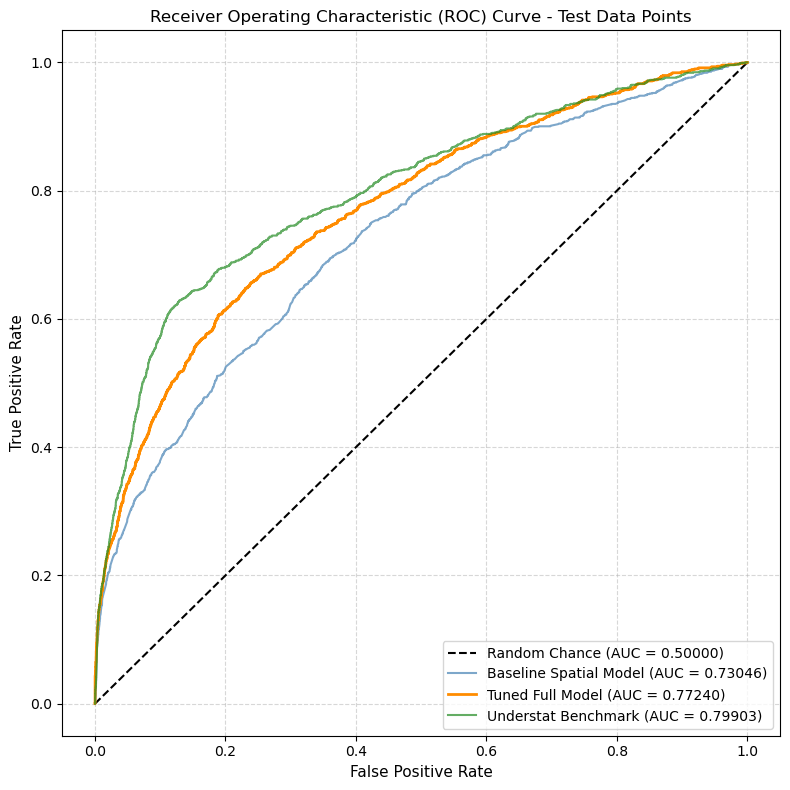

In [9]:
# Compute ROC curve coordinates and AUC scores for each model on the test set
fpr_base, tpr_base, _ = roc_curve(y_test, preds_test)
auc_base = roc_auc_score(y_test, preds_test)

fpr_tuned, tpr_tuned, _ = roc_curve(y_test, tuned_test_preds)
auc_tuned = roc_auc_score(y_test, tuned_test_preds)

fpr_prov, tpr_prov, _ = roc_curve(y_test, Understat_test_xg)
auc_prov = roc_auc_score(y_test, Understat_test_xg)

# Plot ROC Curves
plt.figure(figsize=(8, 8))

# Reference line for random guessing (AUC = 0.50)
plt.plot([0, 1], [0, 1], "k--", label="Random Chance (AUC = 0.50000)")

# Plot individual model ROC curves
plt.plot(fpr_base,tpr_base,color="steelblue",alpha=0.7,label=f"Baseline Spatial Model (AUC = {auc_base:.5f})")
plt.plot(fpr_tuned,tpr_tuned,color="darkorange",linewidth=2,label=f"Tuned Full Model (AUC = {auc_tuned:.5f})")
plt.plot(fpr_prov,tpr_prov,color="forestgreen",alpha=0.7,label=f"Understat Benchmark (AUC = {auc_prov:.5f})")

plt.xlabel("False Positive Rate", fontsize=11)
plt.ylabel("True Positive Rate", fontsize=11)
plt.title("Receiver Operating Characteristic (ROC) Curve - Test Data Points", fontsize=12)
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

This curve looks as expected, the baseline model is a gradual arch with some bowing toward the middle, it lacks the steep initial climb the others have which seperates dangerous shots from routine ones. The steepness of our tuned model between a $0$ and $0.2$ false positive rate tells us that it can catch real goals with low false alarm rates. 

### Feature Attribution & Gain Analysis
Tree feature importance is measured by Gain, being the average reduction in Log Loss brought by splits on a given feature across all trees in the ensemble. We extract these importances to verify that situational and tactical variables add predictive value. [3]

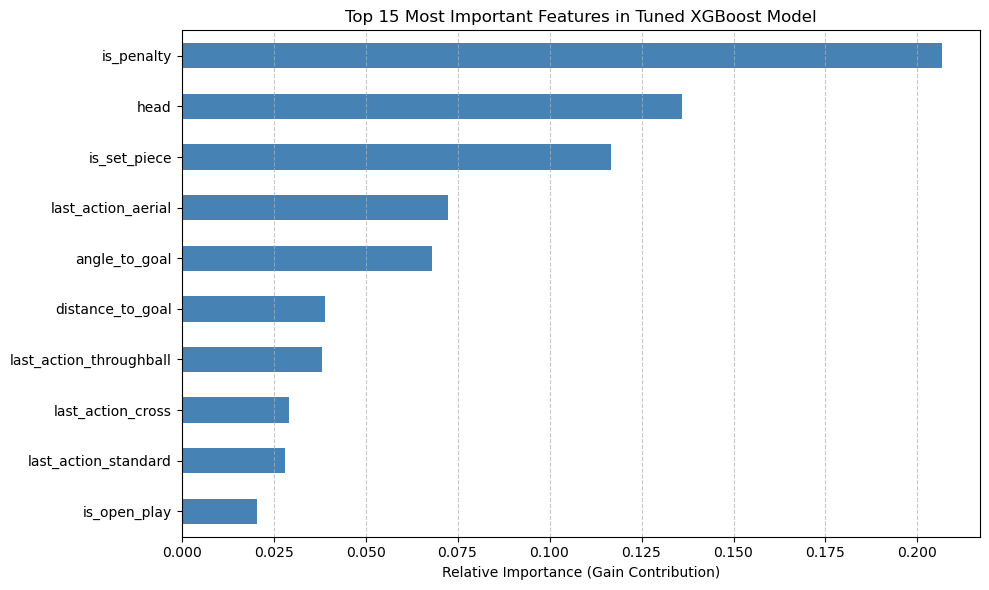

In [10]:
# Plot Top 10 Feature Importances
importances = pd.Series(best_model.feature_importances_, index=features)
top_15 = importances.nlargest(10).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
top_15.plot(kind="barh", color="steelblue")
plt.title("Top 15 Most Important Features in Tuned XGBoost Model", fontsize=12)
plt.xlabel("Relative Importance (Gain Contribution)")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

We can see that there are three large contributors, "is_penalty" is simple to decipher why is so heavily weighted, penalties convert at around $\approx 79%$ as opposed to other shots which are around $\approx 10%$, a single leaf split on "is_penalty" decreases logloss significantly. For "head", this is based on shot mechanics, a header has a much smaller chance of going in than foot shots from identical coordinates, and "set_piece" is high as set pieces alter defensive structure and goalkeeper position in comparison to fluid in-game plays.

### Probability Calibration & Reliability Diagrams
A probabilistic model is perfectly calibrated if its predicted probabilities equal the empirical outcome frequencies:

$$P(Y=1 \mid \hat{p} = p) = p, \quad \forall p \in [0, 1]$$

A Reliability Diagram partitions predicted probabilities into bins (e.g., $[0, 0.1), [0.1, 0.2)$) and plots the mean predicted probability of each bin against the true actual goal rate in that bin. Points along $y = x$ indicate ideal calibration. This reveals whether our model is systematically overconfident or underconfident.

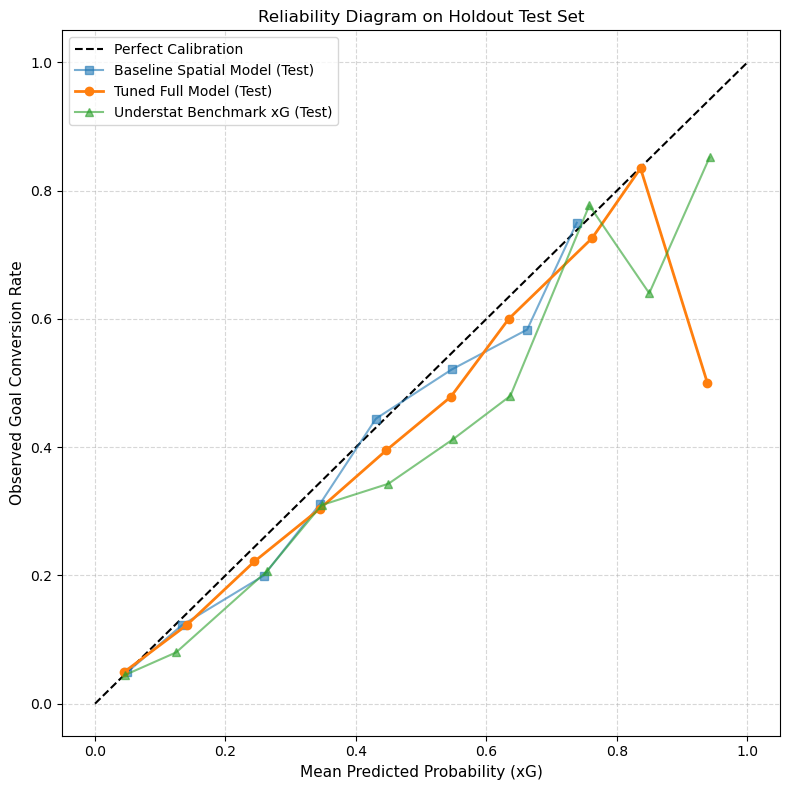

In [17]:
#All 3 models compared on exact same Holdout Test Set:
prob_true_base, prob_pred_base = calibration_curve(y_test, preds_test, n_bins=10)
prob_true_tuned, prob_pred_tuned = calibration_curve(y_test, tuned_test_preds, n_bins=10)
prob_true_Understat, prob_pred_Understat = calibration_curve(y_test, Understat_test_xg, n_bins=10)

plt.figure(figsize=(8, 8))
plt.plot([0, 1], [0, 1], "k--", label="Perfect Calibration")
plt.plot(prob_pred_base, prob_true_base, "s-", alpha=0.6, label="Baseline Spatial Model (Test)")
plt.plot(prob_pred_tuned, prob_true_tuned, "o-", linewidth=2, label="Tuned Full Model (Test)")
plt.plot(prob_pred_Understat, prob_true_Understat, "^-", alpha=0.6, label="Understat Benchmark xG (Test)")

plt.xlabel("Mean Predicted Probability (xG)", fontsize=11)
plt.ylabel("Observed Goal Conversion Rate", fontsize=11)
plt.title("Reliability Diagram on Holdout Test Set", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Graph Analysis
This graph measures calibration, or whether a shot that has, for example, a 30% probability of going in actually goes in 30% of the time. We can see a dip at around $x\approx0.94$ is due to the miniscule amount of the $\approx 11k$ test shots that actually had an $xG > 0.90$ hence our predicted probability falls back down to $0.5$. Since there are $\approx 6$ shots with $xG > 0.8$, things like a single goal-line clearance, or missed tap-in swings the observed conversion rate by 16.7%. If 3 out of 6 shots in the model's $0.9-1.0$ bin happen to be missed, the rate plummets from $1.0$ down to $0.50$, creating that sharp downward spike at $x \approx 0.94$. 

Understat's model dips earlier at $x\approx 0.64$ 

### Real-World Generalisability: Out-of-Domain Subgroup Analysis
Overall Log Loss can obscure local model failures. To test generalisability, we perform subgroup stress-testing on specific shot types. For example, Headers exhibit lower baseline conversion rates and distinct physical mechanics compared to open-play foot shots. We isolate these to see if our model remains robust across different tactical contexts.

In [12]:
# Subgroup analysis on unseen test set
test_sub_df = df.loc[test_mask].copy()
test_sub_df["tuned_xg"] = tuned_test_preds

# Segment by shot type
headers = test_sub_df[test_sub_df["head"] == 1]
foot_shots = test_sub_df[(test_sub_df["left_foot"] == 1) | (test_sub_df["right_foot"] == 1)]

print("OUT-OF-DOMAIN SUBGROUP STRESS TEST (TEST SET)")
print(f"Header Shots Log Loss:     {log_loss(headers['result'], headers['tuned_xg']):.5f} | Observed Goal Rate: {headers['result'].mean():.3f}")
print(f"Foot Shots Log Loss:       {log_loss(foot_shots['result'], foot_shots['tuned_xg']):.5f} | Observed Goal Rate: {foot_shots['result'].mean():.3f}")
print("-" * 60)
print(f"Understat Header Log Loss:   {log_loss(headers['result'], headers['xg']):.5f}")
print(f"Understat Foot Shot Log Loss:{log_loss(foot_shots['result'], foot_shots['xg']):.5f}")

OUT-OF-DOMAIN SUBGROUP STRESS TEST (TEST SET)
Header Shots Log Loss:     0.27706 | Observed Goal Rate: 0.102
Foot Shots Log Loss:       0.28060 | Observed Goal Rate: 0.106
------------------------------------------------------------
Understat Header Log Loss:   0.26609
Understat Foot Shot Log Loss:0.26890


### Critical Model Limitations & Reflections
1. **Lack of Defender Tracking Data (Freeze-Frame Spatial Context):** The model lacks exact coordinates for defending players and goalkeeper positioning at the precise moment of shot execution. A shot from 12 yards with the goalkeeper out of position has a drastically different true probability than a shot through a crowded penalty box.
2. **Shot Trajectory & Velocity:** Unobserved physical variables (shot speed, bounce, deflection) limit the maximum achievable Log Loss.
3. **Pre-Shot Sequence Length:** The dataset records only the immediate `last_action` rather than full multi-event sequence paths leading up to the shot.

# References
[1]Christoph Bergmeir, José M. Benítez,
On the use of cross-validation for time series predictor evaluation,Information Sciences,Volume 191,2012,Pages 192-213,ISSN 0020-0255,https://doi.org/10.1016/j.ins.2011.12.028.
(https://www.sciencedirect.com/science/article/pii/S0020025511006773)

[2]Understat (2026) Understat: Advanced Football Statistics. Available at: https://understat.com (Accessed: 28 October 2026).

[3]Chen, T. and Guestrin, C. (2016) 'XGBoost: A Scalable Tree Boosting System', Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining (KDD '16), pp. 785–794.https://doi.org/10.1145/2939672.2939785 (Acessed: 29 October 2026).